In [2]:

import os

from langchain.agents import create_agent
from langchain_groq import ChatGroq
from langchain_community.tools.tavily_search import TavilySearchResults
from langgraph_supervisor import create_supervisor
from langchain_core.messages import AIMessage, ToolMessage
from langchain_ollama import ChatOllama


# ===================================================
# 1. MODEL AND SEARCH TOOL
# ===================================================

# Set GROQ_API_KEY and TAVILY_API_KEY in your environment.

os.environ["TAVILY_API_KEY"]=os.getenv("TAVILY_API_KEY")

os.environ["GROQ_API_KEY"]=os.getenv("GROQ_API_KEY")

# llm = ChatGroq(
#     model="qwen/qwen3.8-27b",
#     temperature=0,
#     max_tokens=200
# )

llm = ChatOllama(
    model="qwen2.5:3b",
    base_url="http://localhost:11434"
)

tavily = TavilySearchResults(
    max_results=2,
    search_depth="basic",
    include_raw_content=False
)


# ===================================================
# 2. RESEARCH AGENT
# ===================================================

research_agent = create_agent(
    model=llm,
    tools=[tavily],
    name="research_agent",
    system_prompt="""
    You are a cybersecurity research specialist.

    Responsibilities:
    - Research CVEs using Tavily.
    - Find technical vulnerability descriptions.
    - Identify affected software and versions.
    - Identify trustworthy sources.
    - Return concise findings with URLs.

    Do not invent facts.
    Keep your response under 300 words.
    """
)


# ===================================================
# 3. VULNERABILITY ASSESSMENT AGENT
# ===================================================

vulnerability_agent = create_agent(
    model=llm,
    tools=[],
    name="vulnerability_agent",
    system_prompt="""
    You are a Vulnerability Assessment Specialist.

    Responsibilities:
    - Analyze vulnerability severity.
    - Explain attack prerequisites.
    - Assess potential business impact.
    - Identify affected assets when evidence is provided.
    - Explain prioritization using CVSS and exposure.

    Do not claim to have scanned any systems.
    Do not invent CVSS scores or affected assets.

    Keep your response under 300 words.
    """
)


# ===================================================
# 4. REMEDIATION AGENT
# ===================================================

remediation_agent = create_agent(
    model=llm,
    tools=[],
    name="remediation_agent",
    system_prompt="""
    You are a Vulnerability Remediation Specialist.

    Responsibilities:
    - Recommend vendor-supported fixes.
    - Explain patching strategies.
    - Identify temporary mitigations.
    - Suggest remediation validation steps.
    - Discuss operational considerations.

    Distinguish confirmed fixes from general advice.
    Do not invent patch versions.

    Keep your response under 300 words.
    """
)


# ===================================================
# 5. SECURITY REPORT AGENT
# ===================================================

report_agent = create_agent(
    model=llm,
    tools=[],
    name="report_agent",
    system_prompt="""
    You are a Security Report Writer.

    Prepare a professional security assessment report.

    Include:
    1. Executive summary
    2. Vulnerability overview
    3. Severity and business impact
    4. Affected systems or products
    5. Recommended remediation
    6. Verification steps
    7. References

    Use findings from other agents.
    Do not invent facts or citations.
    """
)


# ===================================================
# 6. CREATE THE ACTUAL LLM SUPERVISOR
# ===================================================

supervisor = create_supervisor(
    agents=[
        research_agent,
        vulnerability_agent,
        remediation_agent,
        report_agent
    ],
    model=llm,
    prompt="""
    You are the Cybersecurity Investigation Supervisor.

    You manage four specialists:
    - research_agent
    - vulnerability_agent
    - remediation_agent
    - report_agent

    Decide which specialist to call based on the user's
    request and the findings available.

    Guidelines:
    - Use research_agent when external facts are needed.
    - Use vulnerability_agent when risk analysis is needed.
    - Use remediation_agent when fixes or mitigations are needed.
    - Use report_agent when the investigation is sufficient
      to prepare the requested final report.
    - If important information is missing, delegate
      additional research before finalizing.
    - Avoid unnecessary repeated delegations.
    - Never claim to have performed a real system scan.
    - Once the requested report is complete, finish.
    """,
    output_mode="full_history"
)

graph = supervisor.compile()


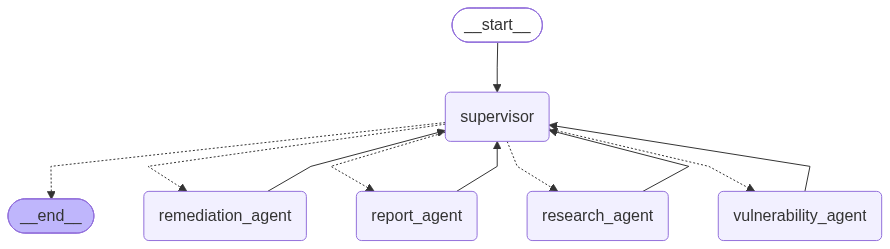

In [3]:
graph

In [4]:
# ===================================================
# 7. RUN THE SUPERVISOR
# ===================================================

user_query = """
Investigate Log4Shell (CVE-2021-44228).

Explain:
- How the vulnerability works.
- Which software may be affected.
- Its security impact.
- Recommended remediation.
- How remediation should be verified.

Prepare a professional security assessment report.
"""

response = graph.invoke(
    {
        "messages": [
            {
                "role": "user",
                "content": user_query
            }
        ]
    },
    config={"recursion_limit": 30}
)


# ===================================================
# 8. PRINT AGENT HANDOFFS AND RESULTS
# ===================================================

print("\n========== EXECUTION HISTORY ==========")

for message in response["messages"]:

    if isinstance(message, AIMessage) and message.tool_calls:
        for call in message.tool_calls:
            print("\nTOOL / AGENT CALLED:", call["name"])
            print("ARGUMENTS:", call["args"])

    elif isinstance(message, ToolMessage):
        print("\nTOOL RESULT:", message.name)
        print(str(message.content)[:2000])

    elif isinstance(message, AIMessage) and message.content:
        print("\nAGENT:", message.name or "assistant")
        print(str(message.content)[:2000])


print("\n========== FINAL OUTPUT ==========")
print(response["messages"][-1].content)



========== EXECUTION HISTORY ==========

TOOL / AGENT CALLED: transfer_to_vulnerability_agent
ARGUMENTS: {}

TOOL RESULT: transfer_to_vulnerability_agent
Successfully transferred to vulnerability_agent

AGENT: vulnerability_agent
### Log4Shell (CVE-2021-44228) Vulnerability Assessment Report

#### Description and Impact:
**Log4Shell** (CVE-2021-44228) is a critical vulnerability in Apache Log4j, a popular logging library. The vulnerability involves a deserialization vulnerability in the Java-based Log4j libraries, leading to remote code execution (RCE) if improperly configured. Attackers can exploit this vulnerability by crafting specially crafted HTTP requests to hijack the JVM, executing arbitrary code.

**Software Affected:**
- Apache Log4j versions prior to 2.15.0 and 2.16.0.
- Log4j is included in numerous third-party software products and open-source projects.

**Security Impact:**
- The vulnerability allows for remote code execution, granting attackers full control over the aff